# 02 Exploratory data analysis

**Purpose.** See how transformer load behaves: its shape over the day and week, what drives it (heat, EVs, solar, holidays), how it compares with the rating, and when outages happen.

**Data.** `data/sim/` (dev scale, seed 7). Every chart is simulated data.

**Outcome.** The patterns a forecast and a risk model have to capture, and the ones they cannot see.

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from _data import load_tables
from _style import COLORS, DIVERGING, SEQUENTIAL, label

tables = load_tables()
load, transformers, weather = tables["load"], tables["transformers"], tables["weather"]
load = load.merge(transformers[["transformer_id", "rated_kva", "loading_class", "ev_site", "has_jumper"]], on="transformer_id")
load["hour"] = load["ts"].dt.hour + load["ts"].dt.minute / 60
load["day"] = load["ts"].dt.normalize()
day_type = weather.assign(day=weather["ts"].dt.normalize()).groupby("day").agg(
    weather=("weather", "first"), is_holiday=("is_holiday", "first"), max_heat_index_c=("heat_index_c", "max"),
    rain_mm=("rain_mm_h", lambda r: r.sum() / 4),
)
day_type["day_kind"] = np.where(day_type["is_holiday"], "holiday", np.where(day_type.index.day_of_week >= 5, "weekend", "weekday"))
load = load.merge(day_type, left_on="day", right_index=True)
CLASS_ORDER = ["light", "normal", "tight", "over"]

## 1. Univariate: how are the main values distributed?

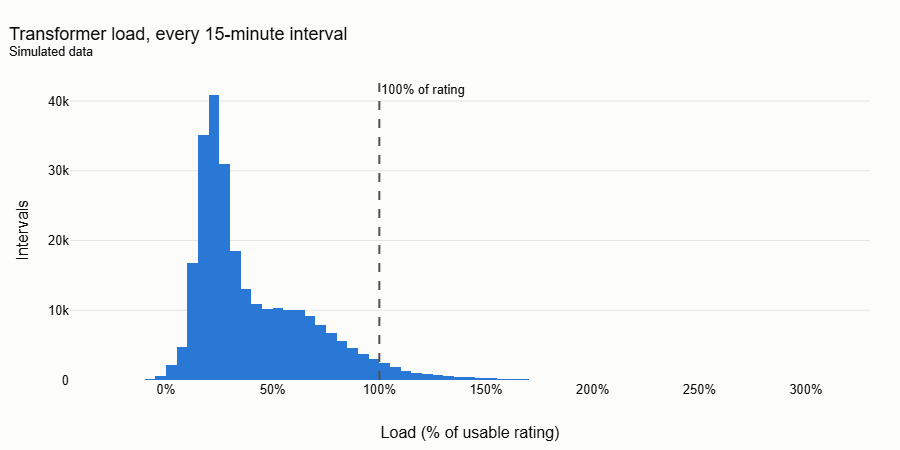

In [2]:
fig = px.histogram(load, x="load_pct", nbins=120, color_discrete_sequence=COLORS[:1])
fig.update_xaxes(tickformat=".0%")
fig.add_vline(x=1.0, line_dash="dash", line_color="#52514e", annotation_text="100% of rating")
label(fig, "Transformer load, every 15-minute interval", "Load (% of usable rating)", "Intervals").show()

Takeaway: most intervals sit well under the rating; a long right tail crosses 100%, and a thin left tail goes below zero where solar homes export at midday.

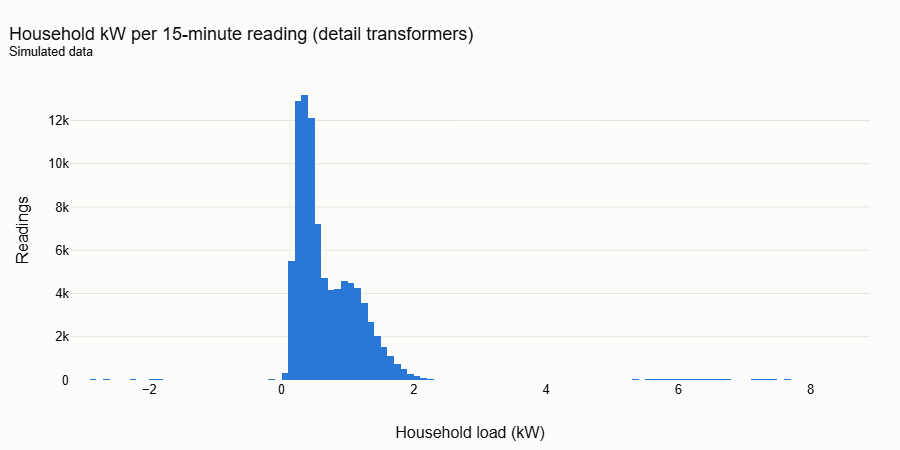

In [3]:
homes = tables["households"].merge(tables["sin_map"][["sin_hash", "has_ev", "solar_kwp"]], on="sin_hash")
fig = px.histogram(homes, x="power_kw", nbins=120, color_discrete_sequence=COLORS[:1])
label(fig, "Household kW per 15-minute reading (detail transformers)", "Household load (kW)", "Readings").show()

Takeaway: a typical home draws under 2 kW; the tail above 4 kW is EV charging, the negative tail is rooftop solar.

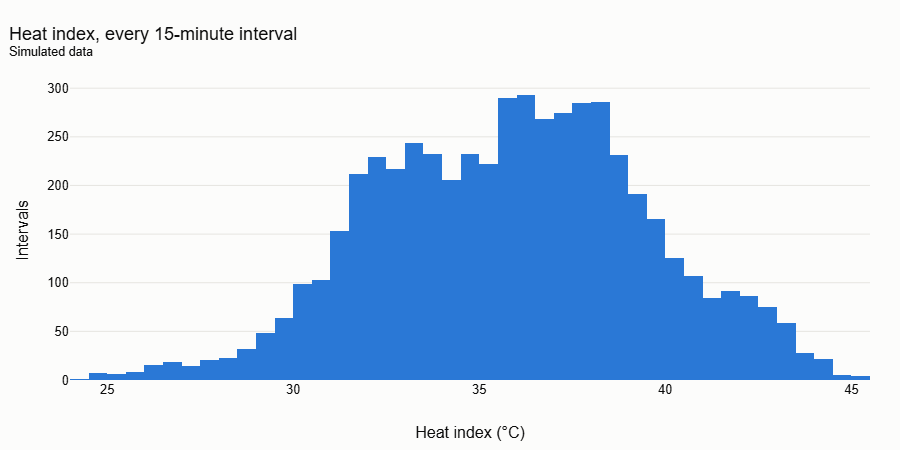

In [4]:
fig = px.histogram(weather, x="heat_index_c", nbins=60, color_discrete_sequence=COLORS[:1])
label(fig, "Heat index, every 15-minute interval", "Heat index (°C)", "Intervals").show()

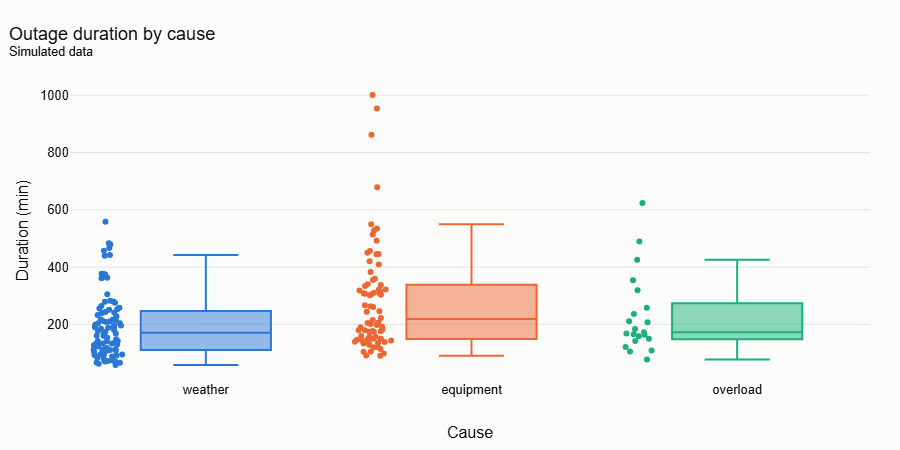

In [5]:
outages = tables["outages"]
fig = px.box(outages, x="cause", y="duration_min", points="all", color="cause", color_discrete_sequence=COLORS)
fig.update_layout(showlegend=False)
label(fig, "Outage duration by cause", "Cause", "Duration (min)").show()

Takeaway: restorations take two to four hours at the median, with a long tail (lognormal by design, silip-domain).

## 2. Time series: what does load look like over time?

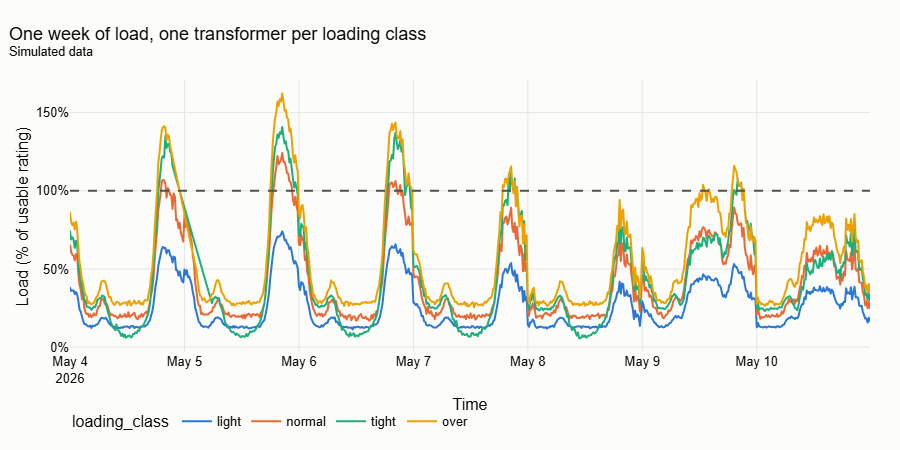

In [6]:
picks = transformers.groupby("loading_class").first().reindex(CLASS_ORDER)["transformer_id"]
week = load[load["transformer_id"].isin(picks) & (load["ts"] >= "2026-05-04") & (load["ts"] < "2026-05-11")]
fig = px.line(week, x="ts", y="load_pct", color="loading_class", category_orders={"loading_class": CLASS_ORDER}, color_discrete_sequence=COLORS)
fig.update_yaxes(tickformat=".0%")
fig.add_hline(y=1.0, line_dash="dash", line_color="#52514e")
label(fig, "One week of load, one transformer per loading class", "Time", "Load (% of usable rating)").show()

Takeaway: a sharp evening peak every day; the overloaded transformer crosses 100% most evenings, the light one never comes close.

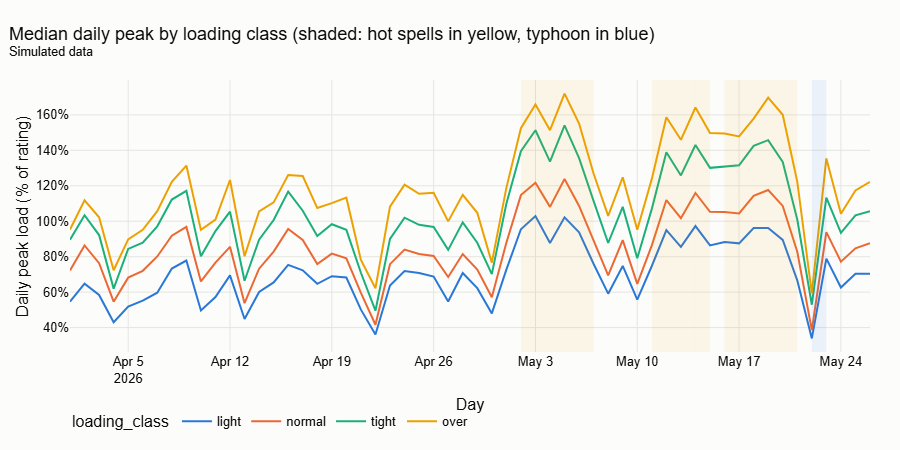

In [7]:
daily_peak = load.groupby(["transformer_id", "day", "loading_class"])["load_pct"].max().reset_index()
by_class = daily_peak.groupby(["day", "loading_class"])["load_pct"].median().reset_index()
fig = px.line(by_class, x="day", y="load_pct", color="loading_class", category_orders={"loading_class": CLASS_ORDER}, color_discrete_sequence=COLORS)
fig.update_yaxes(tickformat=".0%")
for day, row in day_type[day_type["weather"].isin(["hot_spell", "typhoon"])].iterrows():
    fig.add_vrect(x0=day, x1=day + pd.Timedelta(days=1), fillcolor="#eda100" if row["weather"] == "hot_spell" else "#2a78d6", opacity=0.08, line_width=0)
label(fig, "Median daily peak by loading class (shaded: hot spells in yellow, typhoon in blue)", "Day", "Daily peak load (% of rating)").show()

Takeaway: every class moves together with the weather: hot spells lift the peak, the typhoon day drops it.

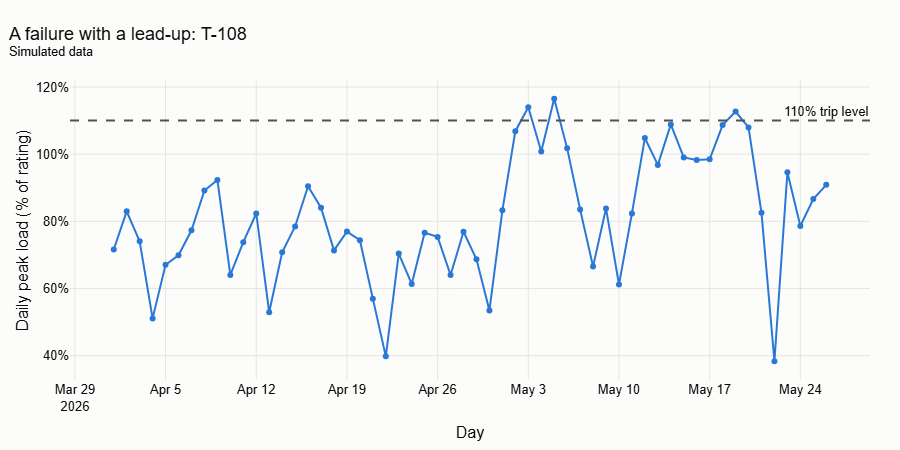

In [8]:
lead = transformers.loc[transformers["lead_up"], "transformer_id"]
if len(lead):
    one = daily_peak[daily_peak["transformer_id"] == lead.iloc[0]]
    trips = outages[(outages["transformer_id"] == lead.iloc[0]) & (outages["cause"] == "overload")]
    fig = px.line(one, x="day", y="load_pct", markers=True, color_discrete_sequence=COLORS[:1])
    fig.update_yaxes(tickformat=".0%")
    fig.add_hline(y=1.1, line_dash="dash", line_color="#52514e", annotation_text="110% trip level")
    for start in trips["start_ts"]:
        fig.add_vline(x=start, line_color="#e34948", annotation_text="overload outage")
    label(fig, f"A failure with a lead-up: {lead.iloc[0]}", "Day", "Daily peak load (% of rating)").show()

Takeaway: the lead-up transformer's peak creeps up for days before it trips. That slow climb is what an early warning should catch.

## 3. Bivariate: what drives load?

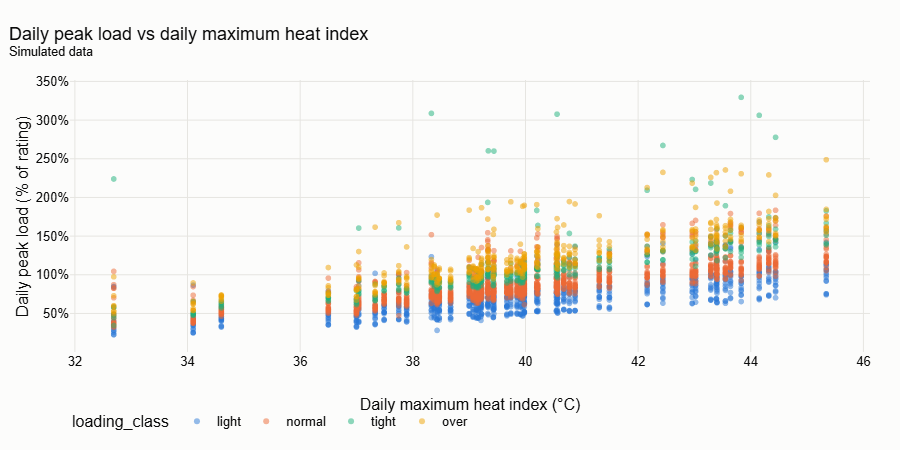

correlation, peak load vs max heat index: 0.60


In [9]:
tx_day = load.groupby(["transformer_id", "day", "loading_class", "weather", "day_kind"]).agg(
    peak_pct=("load_pct", "max"), mean_kw=("transformer_kw", "mean"), max_heat_index_c=("max_heat_index_c", "first")
).reset_index()
fig = px.scatter(tx_day, x="max_heat_index_c", y="peak_pct", color="loading_class", opacity=0.5, category_orders={"loading_class": CLASS_ORDER}, color_discrete_sequence=COLORS)
fig.update_yaxes(tickformat=".0%")
label(fig, "Daily peak load vs daily maximum heat index", "Daily maximum heat index (°C)", "Daily peak load (% of rating)").show()
print(f"correlation, peak load vs max heat index: {tx_day[['max_heat_index_c', 'peak_pct']].corr().iloc[0, 1]:.2f}")

Takeaway: hotter days mean higher peaks within every class: aircon follows the heat index.

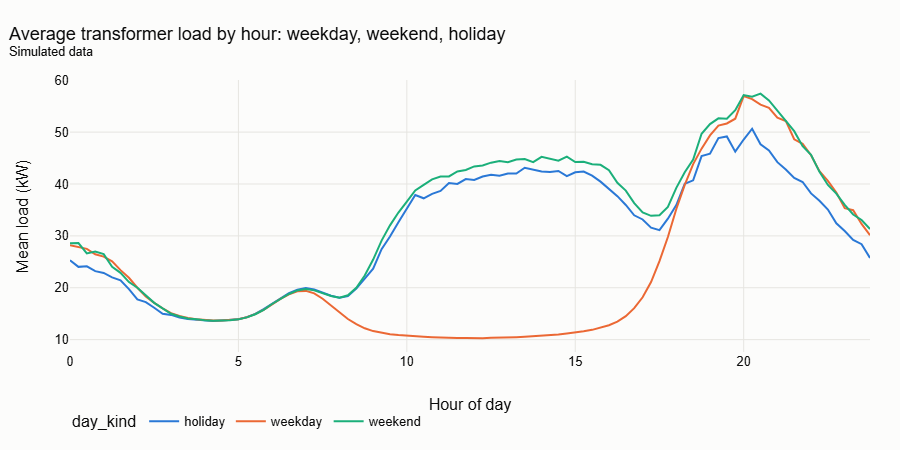

In [10]:
profile = load.groupby(["day_kind", "hour"])["transformer_kw"].mean().reset_index()
fig = px.line(profile, x="hour", y="transformer_kw", color="day_kind", color_discrete_sequence=COLORS)
label(fig, "Average transformer load by hour: weekday, weekend, holiday", "Hour of day", "Mean load (kW)").show()

Takeaway: weekends and holidays carry more daytime load (people at home); the evening peak is similar.

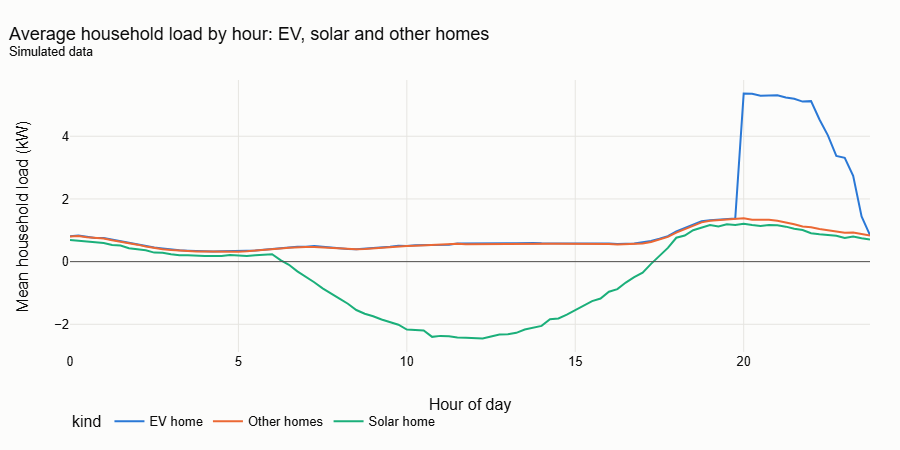

In [11]:
homes["hour"] = homes["ts"].dt.hour + homes["ts"].dt.minute / 60
homes["kind"] = np.select([homes["has_ev"], homes["solar_kwp"] > 0], ["EV home", "Solar home"], "Other homes")
home_profile = homes.groupby(["kind", "hour"])["power_kw"].mean().reset_index()
fig = px.line(home_profile, x="hour", y="power_kw", color="kind", color_discrete_sequence=COLORS)
fig.add_hline(y=0, line_color="#52514e", line_width=1)
label(fig, "Average household load by hour: EV, solar and other homes", "Hour of day", "Mean household load (kW)").show()

Takeaway: EV homes add several kW from 8 PM, on top of the evening peak; solar homes dip below zero around noon. Both shift the transformer's shape, not just its level.

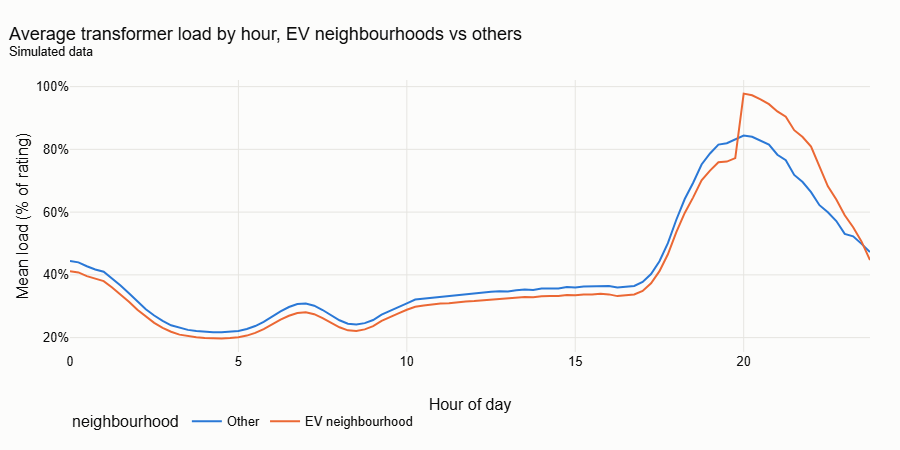

In [12]:
ev_compare = load.groupby(["ev_site", "hour"])["load_pct"].mean().reset_index()
ev_compare["neighbourhood"] = np.where(ev_compare["ev_site"], "EV neighbourhood", "Other")
fig = px.line(ev_compare, x="hour", y="load_pct", color="neighbourhood", color_discrete_sequence=COLORS)
fig.update_yaxes(tickformat=".0%")
label(fig, "Average transformer load by hour, EV neighbourhoods vs others", "Hour of day", "Mean load (% of rating)").show()

Takeaway: EV neighbourhoods carry a later, higher peak that starts at 8 PM, when the evening aircon peak is already high.

## 4. Load against the rating

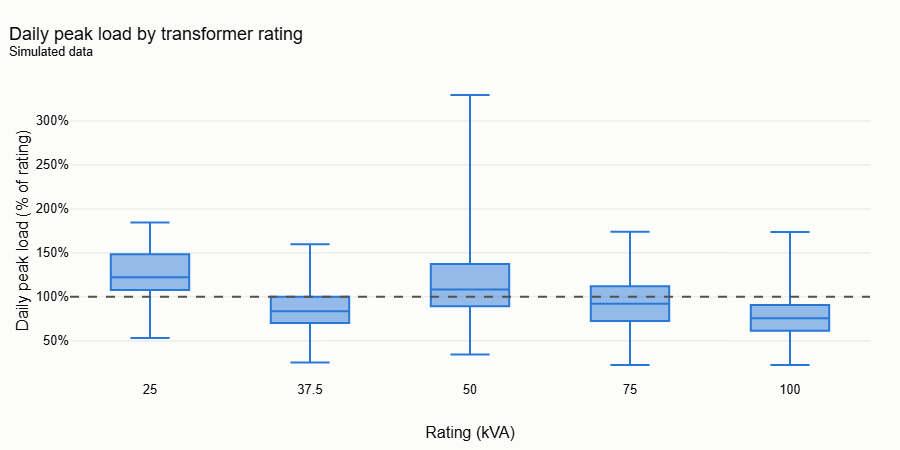

In [13]:
fig = px.box(daily_peak.merge(transformers[["transformer_id", "rated_kva"]]), x="rated_kva", y="load_pct", points=False, color_discrete_sequence=COLORS[:1])
fig.update_yaxes(tickformat=".0%")
fig.update_xaxes(type="category", categoryorder="array", categoryarray=[25.0, 37.5, 50.0, 75.0, 100.0])
fig.add_hline(y=1.0, line_dash="dash", line_color="#52514e")
label(fig, "Daily peak load by transformer rating", "Rating (kVA)", "Daily peak load (% of rating)").show()

Takeaway: overload happens at every rating; rating alone does not tell you which transformer is at risk.

## 5. Multivariate: how do the drivers relate?

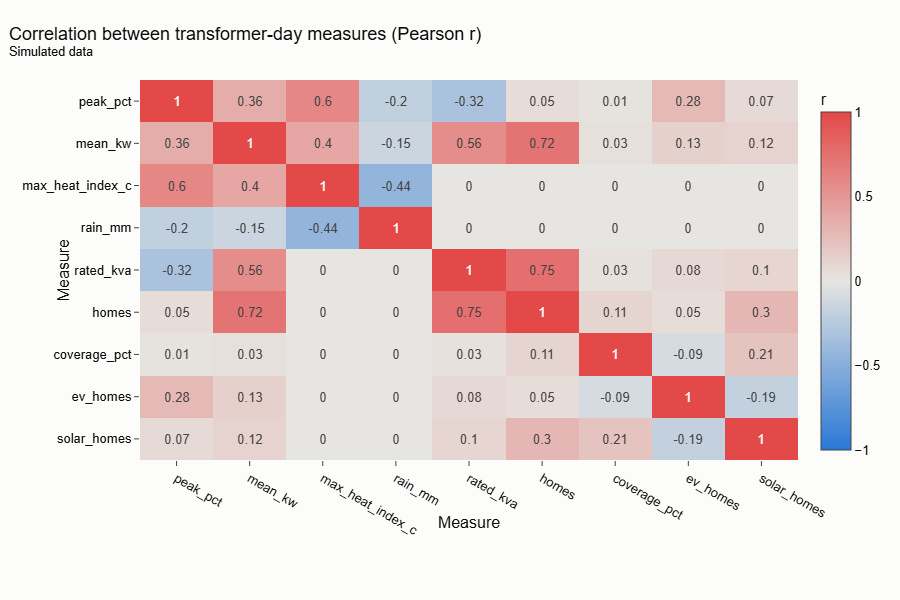

In [14]:
tx_day = tx_day.merge(transformers[["transformer_id", "rated_kva", "homes", "coverage_pct", "ev_homes", "solar_homes"]], on="transformer_id")
tx_day = tx_day.merge(day_type[["rain_mm"]], left_on="day", right_index=True)
corr_columns = ["peak_pct", "mean_kw", "max_heat_index_c", "rain_mm", "rated_kva", "homes", "coverage_pct", "ev_homes", "solar_homes"]
corr = tx_day[corr_columns].corr()
fig = go.Figure(go.Heatmap(z=corr.to_numpy(), x=corr_columns, y=corr_columns, colorscale=DIVERGING, zmin=-1, zmax=1, text=corr.round(2).to_numpy(), texttemplate="%{text}", colorbar={"title": "r"}))
fig.update_yaxes(autorange="reversed")
fig.update_layout(height=600, margin={"l": 140, "b": 140})
label(fig, "Correlation between transformer-day measures (Pearson r)", "Measure", "Measure").show()

Takeaway: peak load % tracks mean kW and heat index; rated kVA and homes move together (transformers are sized for their homes), so neither predicts overload by itself.

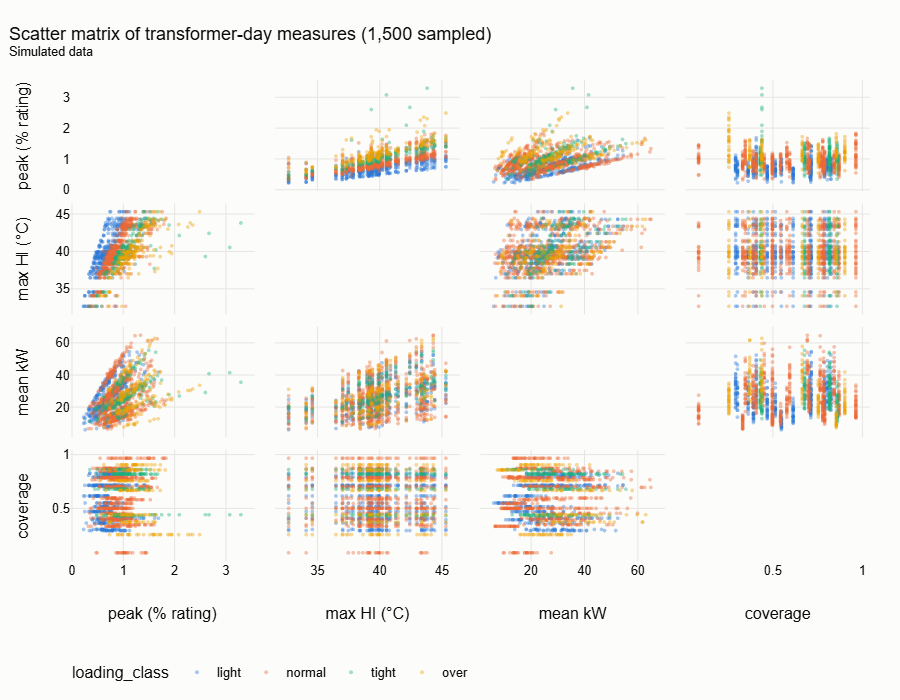

In [15]:
sample = tx_day.sample(1500, random_state=7)
fig = px.scatter_matrix(sample, dimensions=["peak_pct", "max_heat_index_c", "mean_kw", "coverage_pct"], color="loading_class", category_orders={"loading_class": CLASS_ORDER}, color_discrete_sequence=COLORS, opacity=0.4, labels={"peak_pct": "peak (% rating)", "max_heat_index_c": "max HI (°C)", "mean_kw": "mean kW", "coverage_pct": "coverage"})
fig.update_traces(diagonal_visible=False, marker={"size": 4})
fig.update_layout(height=700)
label(fig, "Scatter matrix of transformer-day measures (1,500 sampled)").show()

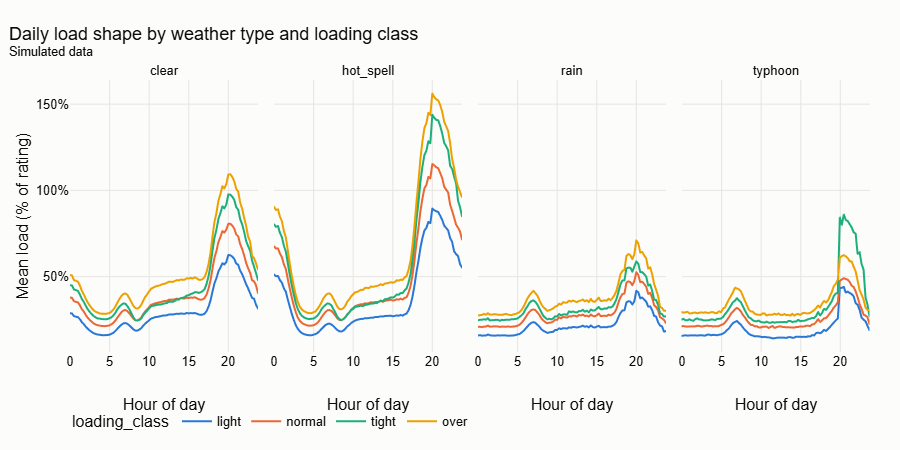

In [16]:
facet = load.groupby(["weather", "loading_class", "hour"])["load_pct"].mean().reset_index()
fig = px.line(facet, x="hour", y="load_pct", color="loading_class", facet_col="weather", facet_col_wrap=4, category_orders={"loading_class": CLASS_ORDER, "weather": ["clear", "hot_spell", "rain", "typhoon"]}, color_discrete_sequence=COLORS)
fig.update_yaxes(tickformat=".0%")
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
label(fig, "Daily load shape by weather type and loading class", "Hour of day")
fig.for_each_yaxis(lambda axis: axis.update(title_text=""))
fig.update_yaxes(title_text="Mean load (% of rating)", col=1)
fig.show()

Takeaway: hot spells raise the evening peak for every class; on the typhoon day load drops and outages cut it to zero in places.

## 6. Outages vs load and weather

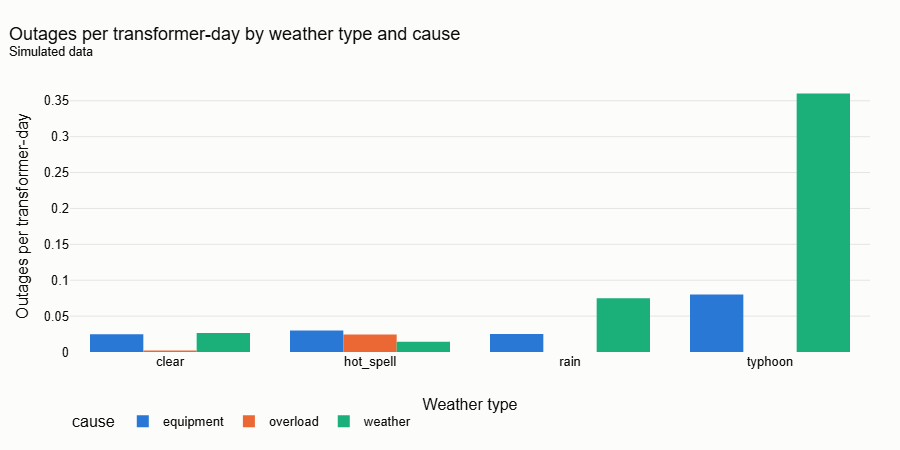

In [17]:
outage_days = outages.assign(day=outages["start_ts"].dt.normalize()).merge(day_type[["weather"]], left_on="day", right_index=True)
rate = (outage_days.groupby(["weather", "cause"]).size() / day_type["weather"].value_counts() / len(transformers)).rename("per_tx_day").reset_index()
fig = px.bar(rate, x="weather", y="per_tx_day", color="cause", barmode="group", color_discrete_sequence=COLORS, category_orders={"weather": ["clear", "hot_spell", "rain", "typhoon"]})
label(fig, "Outages per transformer-day by weather type and cause", "Weather type", "Outages per transformer-day").show()

Takeaway: weather outages jump on rain and typhoon days; overload outages come only on hot-spell days.

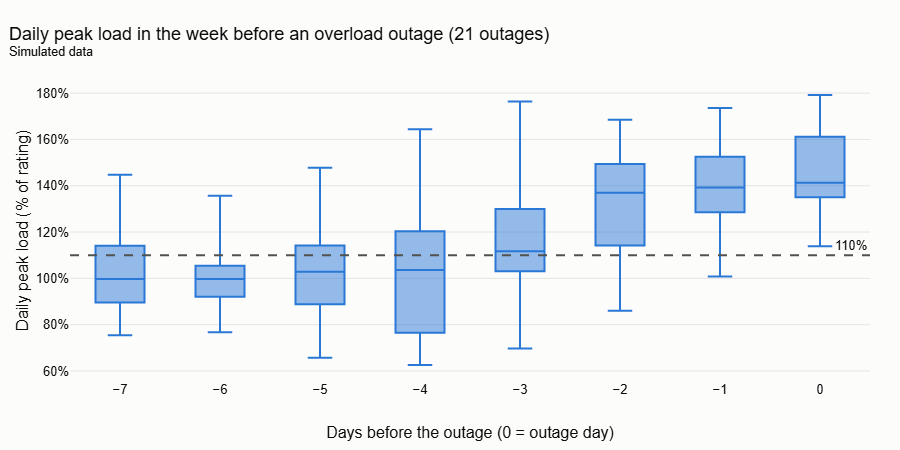

In [18]:
overload = outages[outages["cause"] == "overload"].assign(day=lambda o: o["start_ts"].dt.normalize())
before = []
for _, outage in overload.iterrows():
    peaks = daily_peak[daily_peak["transformer_id"] == outage["transformer_id"]].set_index("day")["load_pct"]
    for lag in range(0, 8):
        day = outage["day"] - pd.Timedelta(days=lag)
        if day in peaks.index:
            before.append({"days_before": -lag, "peak_pct": peaks[day]})
before = pd.DataFrame(before)
fig = px.box(before, x="days_before", y="peak_pct", points=False, color_discrete_sequence=COLORS[:1])
fig.update_yaxes(tickformat=".0%")
fig.add_hline(y=1.1, line_dash="dash", line_color="#52514e", annotation_text="110%")
label(fig, f"Daily peak load in the week before an overload outage ({len(overload)} outages)", "Days before the outage (0 = outage day)", "Daily peak load (% of rating)").show()

Takeaway: transformers that trip were already above 110% on earlier days (the trip rule needs three such days). Yesterday's peak is a strong warning sign.

## 7. Missingness: where and when is data missing?

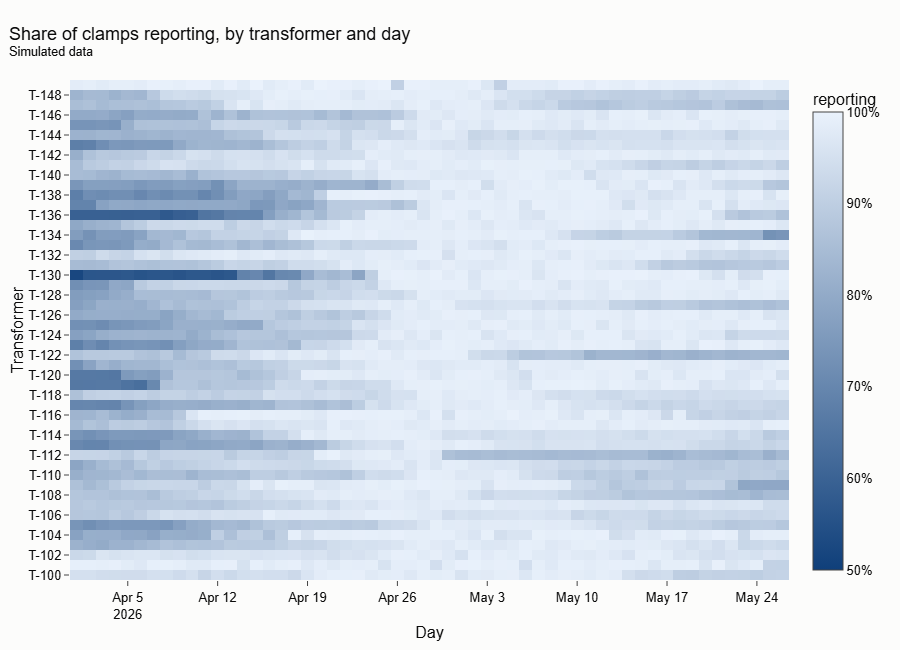

In [19]:
clamped = tables["sin_map"].groupby("transformer_id")["has_clamp"].sum()
miss = load.merge(clamped.rename("clamped"), on="transformer_id")
miss["reporting"] = miss["homes_reporting"] / miss["clamped"]
heat = miss.groupby(["transformer_id", "day"])["reporting"].mean().unstack()
fig = go.Figure(go.Heatmap(z=heat.to_numpy(), x=heat.columns, y=heat.index, colorscale=[[0, SEQUENTIAL[3]], [1, SEQUENTIAL[0]]], zmin=0.5, zmax=1, colorbar={"title": "reporting", "tickformat": ".0%"}))
label(fig, "Share of clamps reporting, by transformer and day", "Day", "Transformer")
fig.update_layout(height=650)
fig.show()

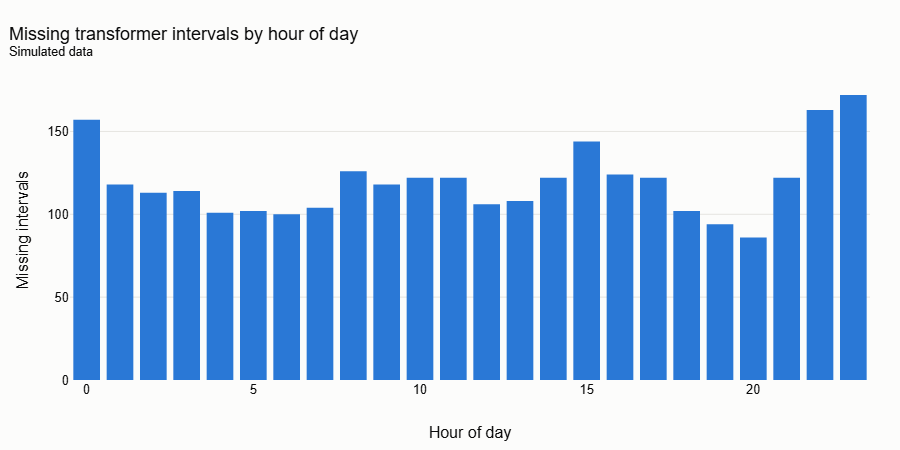

In [20]:
expected = pd.MultiIndex.from_product([load["transformer_id"].unique(), pd.date_range(load["ts"].min(), load["ts"].max(), freq="15min")])
present = pd.MultiIndex.from_frame(load[["transformer_id", "ts"]])
missing = expected.difference(present).to_frame(index=False, name=["transformer_id", "ts"])
by_hour = missing.groupby(missing["ts"].dt.hour).size().reindex(range(24), fill_value=0).rename("missing").reset_index()
fig = px.bar(by_hour, x="ts", y="missing", color_discrete_sequence=COLORS[:1])
label(fig, "Missing transformer intervals by hour of day", "Hour of day", "Missing intervals").show()

Takeaway: late installs show as darker early columns, dead clamps as rows that darken mid-run. Whole intervals go missing only during outages, most often in the evening, when overload trips happen.

**Outcome.** Load follows heat, the evening peak and the day type; EVs and solar change the shape; overload builds over days before a trip. Weather drives most day-to-day change, but the scoring job has no weather feed yet, so `03` checks how much that costs.